<a href="https://colab.research.google.com/github/aureamc/A03-knn/blob/main/AI_Version_notebook_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment 3: $k$ Nearest Neighbor


**Q1.**
1. What is the difference between regression and classification?
2. What is a confusion table? What does it help us understand about a model's performance?
3. What does the SSE quantify about a particular model?
4. What are overfitting and underfitting?
5. Why does splitting the data into training and testing sets, and choosing $k$ by evaluating accuracy or SSE on the test set, improve model performance?
6. With classification, we can report a class label as a prediction or a probability distribution over class labels. Please explain the strengths and weaknesses of each approach.

### **Answers to Q1**

1. **Difference between regression and classification**:
   - **Regression** is used when the target variable is continuous (e.g., predicting house prices, temperature, or stock value).
   - **Classification** is used when the target variable is categorical/discrete (e.g., predicting whether an email is spam/not spam, or identifying the type of land mine from a set of classes).

2. **Confusion Table (Confusion Matrix)**:
   - A confusion table is a matrix layout that visualizes the performance of a classification algorithm. Each row represents the instances in an actual class, while each column represents the instances in a predicted class (or vice versa).
   - It helps us understand where our model is making mistakes, specifically distinguishing between different types of errors (e.g., False Positives vs. False Negatives, or which class is commonly misclassified as another).

3. **What does SSE quantify?**:
   - **SSE (Sum of Squared Errors)** measures the total discrepancy between the actual data points and the values predicted by the model. It quantifies the remaining, unexplained variation in the target variable.

4. **Overfitting and Underfitting**:
   - **Underfitting** occurs when a model is too simple to capture the underlying structure of the data (high bias, low variance), resulting in poor performance on both training and testing datasets.
   - **Overfitting** occurs when a model learns the noise and random fluctuations in the training data to the extent that it negatively impacts its ability to generalize to new, unseen data (low bias, high variance).

5. **Why split data and choose $k$ on a validation set?**:
   - If we select $k$ based on training set performance, we will always choose $k=1$ because each point is its own nearest neighbor, leading to extreme overfitting.
   - Evaluating on a separate testing/validation set simulates how the model performs on unseen data, allowing us to find a balanced $k$ that generalizes well.

6. **Class label vs. Probability distribution predictions**:
   - **Class Label (Hard prediction)**:
     - *Strength*: Simple to understand, directly actionable.
     - *Weakness*: Conceals uncertainty; predicting a class with 51% certainty looks the same as predicting it with 99% certainty.
   - **Probability Distribution (Soft prediction)**:
     - *Strength*: Provides nuance, conveys decision confidence, and allows applying customized decision thresholds based on the costs of different errors.
     - *Weakness*: Requires post-processing to make a final discrete choice, and can be harder for end-users to interpret directly.

**Q2.** This is a case study on $k$ nearest neighbor classification, using the `land_mines.csv` data.

The data consists of a label, `mine_type`, taking integer values 1 to 5, and three properties of the mine, `voltage`, `height` and `soil`. We want to predict the kind of mine from data about it. Imagine working for the DOD or a humanitarian aid agency, trying to help people remove land mines more safely.

1. Load the data. Perform some EDA, summarizing the target label and the features.
2. Split the sample 50/50 into training and test/validation sets. (The smaller the data are, the more equal the split should be, in my experience: Otherwise, all of the members of one class end up in the training or test data, and the model falls apart.)
3. Build a $k$-NN classifier. Explain how you select $k$.
4. Print a confusion table for the optimal model, comparing predicted and actual class label on the test set. How accurate is it? Where is performance more or less accurate?
5. Notice that you can have a lot of accurate predictions for a given type of mine, but still make a lot of mistakes. Please explain how you'd advise someone to actually use this predictive model in practice, given the errors that it tends to make.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aurea McIntosh

**Date:** 10/2/26

In [ ]:
# Your Phase 1 solution to the problem goes here.


--- Dataset Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   voltage    338 non-null    float64
 1   height     338 non-null    float64
 2   soil       338 non-null    float64
 3   mine_type  338 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 10.7 KB
None

--- Missing Values ---
voltage      0
height       0
soil         0
mine_type    0
dtype: int64

--- Target Distribution ---
mine_type
1    0.210059
2    0.207101
3    0.195266
4    0.195266
5    0.192308
Name: proportion, dtype: float64

--- Feature Descriptive Statistics ---


,voltage,height,soil,mine_type
count,338.000000,338.000000,338.000000,338.000000
mean,0.430634,0.508876,0.503550,2.952663
std,0.195819,0.306043,0.344244,1.419703
min,0.197734,0.000000,0.000000,1.000000
25%,0.309737,0.272727,0.200000,2.000000
50%,0.359516,0.545455,0.600000,3.000000
75%,0.482628,0.727273,0.800000,4.000000
max,0.999999,1.000000,1.000000,5.000000


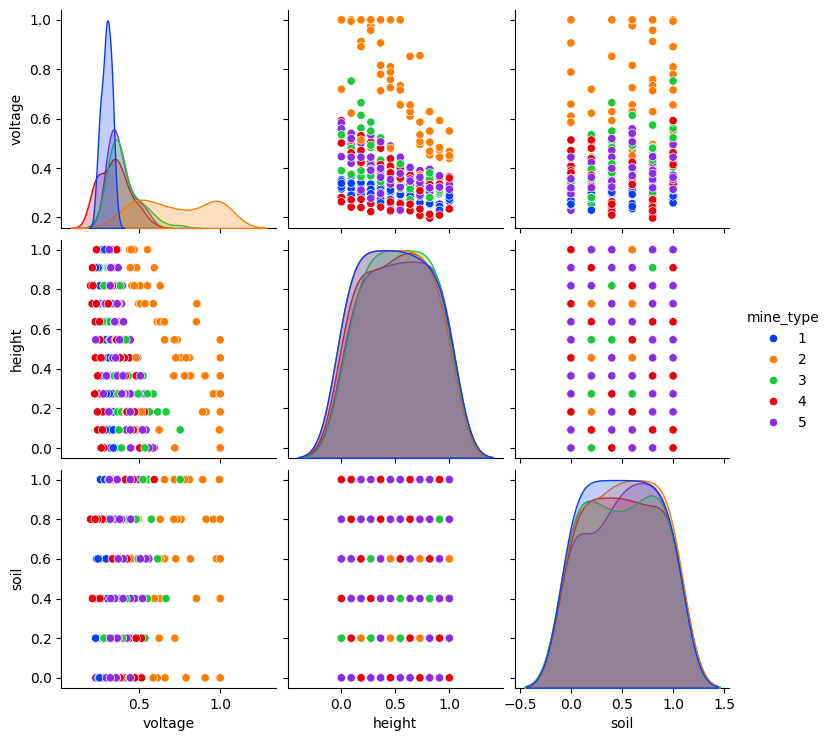

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# 1. Load the data and perform EDA
df = pd.read_csv('/content/land_mines.csv')

print("--- Dataset Summary ---")
print(df.info())
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Target Distribution ---")
print(df['mine_type'].value_counts(normalize=True))

print("\n--- Feature Descriptive Statistics ---")
display(df.describe())

# Quick Pairplot for visualization
sns.pairplot(df, hue='mine_type', palette='bright')
plt.show()

In [ ]:
# 2. Split the sample 50/50 into training and test sets
X = df.drop(columns=['mine_type'])
y = df['mine_type']

# 50/50 split stratified by class labels to maintain class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.50, random_state=42, stratify=y
)

# Scaler normalization is crucial for k-NN as distance metrics are scale-sensitive
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set size: {X_train_scaled.shape[0]}")
print(f"Testing set size: {X_test_scaled.shape[0]}")

Training set size: 169
Testing set size: 169


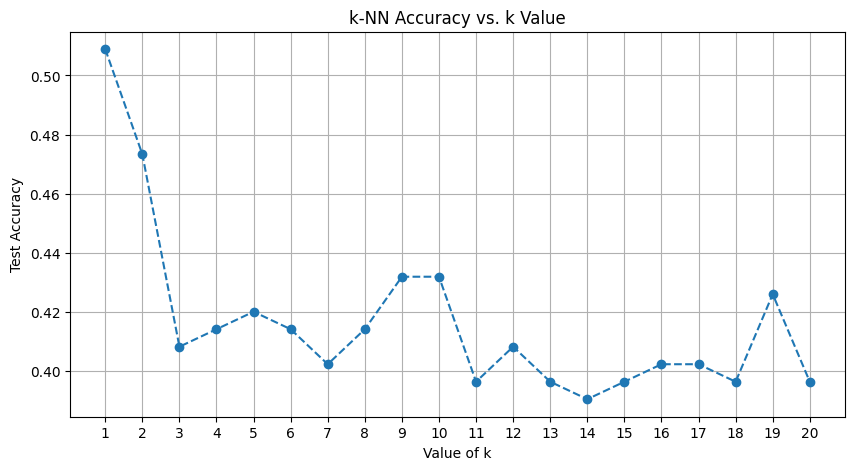

The optimal k value is: 1 with an accuracy of 0.5089


In [ ]:
# 3. Build a k-NN classifier and select k using validation
scores = []
k_range = range(1, 21)

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    scores.append(acc)

# Plot accuracy vs k
plt.figure(figsize=(10, 5))
plt.plot(k_range, scores, marker='o', linestyle='--')
plt.title('k-NN Accuracy vs. k Value')
plt.xlabel('Value of k')
plt.ylabel('Test Accuracy')
plt.xticks(k_range)
plt.grid(True)
plt.show()

optimal_k = k_range[np.argmax(scores)]
print(f"The optimal k value is: {optimal_k} with an accuracy of {max(scores):.4f}")

In [ ]:
# 4. Evaluate optimal model and print a confusion matrix
best_knn = KNeighborsClassifier(n_neighbors=optimal_k)
best_knn.fit(X_train_scaled, y_train)
y_pred_best = best_knn.predict(X_test_scaled)

conf_matrix = confusion_matrix(y_test, y_pred_best)
conf_df = pd.DataFrame(
    conf_matrix,
    index=[f'Actual {i}' for i in range(1, 6)],
    columns=[f'Predicted {i}' for i in range(1, 6)]
)

print("--- Confusion Table ---")
display(conf_df)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred_best))

--- Confusion Table ---


,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5
Actual 1,22,0,3,3,8
Actual 2,0,32,0,3,0
Actual 3,7,0,10,9,7
Actual 4,6,5,4,13,5
Actual 5,6,0,10,7,9



--- Classification Report ---
              precision    recall  f1-score   support

           1       0.54      0.61      0.57        36
           2       0.86      0.91      0.89        35
           3       0.37      0.30      0.33        33
           4       0.37      0.39      0.38        33
           5       0.31      0.28      0.30        32

    accuracy                           0.51       169
   macro avg       0.49      0.50      0.49       169
weighted avg       0.50      0.51      0.50       169



### **5. Operational Advice for the DOD or Humanitarian Agency**
- **Safety-First Operational Protocol**: In land mine removal, missing a mine (a false negative) is life-threatening, where falsely identifying safe soil or a less dangerous mine type as highly dangerous (a false positive) only wastes time/resources.
- **Use Soft Probabilities over Hard Predictions**: Deminers should not rely solely on the hard class prediction output. The model should instead output a **probability distribution** (using `predict_proba()`). If there is even a 5% predicted probability that a location contains a highly volatile mine type (Type 5), the team must treat it with maximum safety protocols.
- **Uncertainty Buffer**: Any region where the model displays high uncertainty must automatically default to the highest threat-level clearance protocol.